# PPMI Modality Analysis: Neurobehavioral, Sleep & Autonomic Systems
**Notebook**: `eda_pca_neurobehavioral_sleep_autonomic.ipynb`  
**Modality Group**: `neurobehavioral_sleep_autonomic` (6 Scoped Analyzable Units)  
**Authoritative Scope**: `docs/important_modality_files.md`  
**Cohort Policy (Revision 4)**: Parkinson's disease (`PD`) and Healthy Controls (`HC`) Only  
**PCA Architecture**: Shared-space class-balanced component space fit on 1 deterministic record per participant  
**Governance Framework**: Codex Supervisory Review & `AGENTS.md` Task `EDA-PCA-001`  

---

## Modality Overview
Non-motor clinical scales including SCOPA-AUT autonomic symptoms, RBDSQ dream enactment, Epworth daytime sleepiness, GDS-15 depression, STAI anxiety, and QUIP impulsive-compulsive behaviors.

### Scientific & Governance Invariants
1. **Target Cohort Restriction**: Analytical populations and PCA models are restricted exclusively to verified **Parkinson's disease (`PD`)** and **Healthy Controls (`HC`)**. Excluded classes (SWEDD, prodromal, genetic non-motor carriers) are filtered out prior to analysis. Cohort labels and disease staging fields never enter the PCA feature matrix.
2. **Participant-Level Shared-Space PCA**: For eligible participant-level tables, repeated visits are resolved to 1 record per participant (baseline preferred with stable tie-breaking and completeness checks). PCA and preprocessing (median imputation, scaling) are fit exclusively on a shared, deterministically class-balanced sample ($k = \min(N_{PD}, N_{HC})$, sampled via SHA-256 hash ranking) to reduce direct sample-count influence on component orientation, and all target participants are projected into this identical space.
3. **Comprehensive Committed EDA (Correction C1 / R4-02)**: Exact schemas with variable roles, missingness, duplicate rows, observation grain, numeric skewness, Tukey IQR and z-score outlier metrics, and categorical frequency summaries are visibly rendered in this notebook and committed directly to disk.
4. **Privacy-Safe Displays (Correction C3 / R4-05)**: Scree plots, loadings tables, and 2x2 side-by-side PD vs HC hexbin density score plots with cell suppression ($< 5$ observations masked) and outlier disclosures.
5. **Committed State Reproducibility (Correction C4 / R4-04)**: Loads directly from committed reports (`EDA/outputs/reports/`) using repository-relative POSIX paths with zero dependence on ignored cache.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Resolve repository root
repo_root = Path.cwd().resolve()
if (repo_root / "EDA" / "src").exists():
    sys.path.insert(0, str(repo_root / "EDA" / "src"))
elif (repo_root.parent / "EDA" / "src").exists():
    repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "EDA" / "src"))

from ppmi_pipeline.reporting.privacy import PrivacyGuard

print(f"Environment initialized. Modality: 'neurobehavioral_sleep_autonomic', Dynamic repository root: ppmi")

Environment initialized. Modality: 'neurobehavioral_sleep_autonomic', Dynamic repository root: ppmi


## 1. Scoped Analyzable Units in Neurobehavioral, Sleep & Autonomic Systems
The authoritative catalog assigns exactly **6 analyzable unit(s)** to this modality domain.

In [2]:
manifest_path = repo_root / "EDA" / "outputs" / "reports" / "priority_eda_pca_manifest.json"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

mod_units = [u for u in manifest_data["units"] if u.get("modality_group") == 'neurobehavioral_sleep_autonomic']

inv_rows = []
for unit_entry in mod_units:
    sheet_suffix = (" -> [" + str(unit_entry.get("sheet_name")) + "]") if unit_entry.get("sheet_name") else ""
    pca_stat_str = ("COMPLETED (" + str(unit_entry.get("pca_included_features_count", 0)) + " feats)") if unit_entry.get("pca_status") == "COMPLETED" else str(unit_entry.get("pca_skip_reason"))
    inv_rows.append({
        "Unit Slug": unit_entry["unit_slug"],
        "Filename / Sheet": str(unit_entry.get("declared_filename")) + sheet_suffix,
        "Physical Exists": "Yes" if unit_entry.get("physical_exists") else "No (Absent)",
        "EDA Status": unit_entry.get("eda_status"),
        "PCA Status": unit_entry.get("pca_status"),
        "PCA Reason / Features": pca_stat_str
    })

inv_df = pd.DataFrame(inv_rows)
display(inv_df)
print(f"Total units cataloged: {len(inv_df)} | EDA Completed: {(inv_df['EDA Status'] == 'COMPLETED').sum()} | PCA Completed: {(inv_df['PCA Status'] == 'COMPLETED').sum()}")

,Unit Slug,Filename / Sheet,Physical Exists,EDA Status,PCA Status,PCA Reason / Features
0,non_motor_SCOPA-AUT_09Nov2026_csv,SCOPA-AUT_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (28 feats)
1,sleep_disorder_REM_Sleep_Behavior_Disorder_Scr...,REM_Sleep_Behavior_Disorder_Screening_Question...,Yes,COMPLETED,COMPLETED,COMPLETED (21 feats)
2,sleep_disorder_Epworth_Sleepiness_Scale_09Nov2...,Epworth_Sleepiness_Scale_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (8 feats)
3,neurobehavioral_Geriatric_Depression_Scale__Sh...,Geriatric_Depression_Scale__Short_Version__09N...,Yes,COMPLETED,COMPLETED,COMPLETED (15 feats)
4,neurobehavioral_State-Trait_Anxiety_Inventory_...,State-Trait_Anxiety_Inventory_for_Adults_09Nov...,Yes,COMPLETED,COMPLETED,COMPLETED (40 feats)
5,neurobehavioral_QUIP-Current-Short_09Nov2026_csv,QUIP-Current-Short_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (13 feats)


Total units cataloged: 6 | EDA Completed: 6 | PCA Completed: 6


---
## 2.1. Unit: `SCOPA-AUT_09Nov2026.csv` 
- **Unit Slug**: `non_motor_SCOPA-AUT_09Nov2026_csv`
- **Source Path**: `non motor/SCOPA-AUT_09Nov2026.csv`
- **Committed Unit Artifact**: [`non_motor_SCOPA-AUT_09Nov2026_csv.json`](../EDA/outputs/reports/units/non_motor_SCOPA-AUT_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Scales for Outcomes in Parkinson's Disease - Autonomic. Detailed evaluation of gastrointestinal, urinary, cardiovascular, thermoregulatory, pupillomotor, and sexual dysfunction.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: non motor/SCOPA-AUT_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 11,608 analyzed rows x 44 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 22,632 (5,342 participants)
  - PD Retained:  9,340 rows (1,680 participants)
  - HC Retained:  2,268 rows (336 participants)
  - Non-Target Excluded: 10,679 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  345 rows

Exact Variable Schema & Storage Types (44 columns):
Showing first 20 of 44 columns (complete schema committed to non_motor_SCOPA-AUT_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"11,608",Identifier
1,PATNO,int64,0,0.0%,"2,016",Identifier
2,EVENT_ID,object,0,0.0%,25,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,PTCGBOTH,float64,1,0.0%,3,Analytical Numeric Measurement
6,SCAU1,float64,2,0.0%,4,Analytical Numeric Measurement
7,SCAU2,float64,1,0.0%,4,Analytical Numeric Measurement
8,SCAU3,float64,2,0.0%,4,Analytical Numeric Measurement
9,SCAU4,float64,3,0.0%,4,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,31
Categorical / Text,4
Date / Timestamp / Visit,3
Identifier,3
Administrative Metadata,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 65,309 / 510,752 (12.79%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (36 total, top 8):


,name,missing_count,missing_percent,variable_role
30,SCAU23AT,"10,470",90.2%,Categorical / Text
36,SCAU26BT,"9,843",84.8%,Categorical / Text
34,SCAU26AT,"8,985",77.4%,Categorical / Text
40,SCAU26DT,"7,606",65.5%,Date / Timestamp / Visit
38,SCAU26CT,"7,528",64.8%,Categorical / Text
32,SCAU25,"5,191",44.7%,Analytical Numeric Measurement
31,SCAU24,"5,186",44.7%,Analytical Numeric Measurement
29,SCAU23A,"3,862",33.3%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"9,340"
1,HC,"2,268"



Numeric Summaries & Outlier Diagnostics (31 continuous/discrete features):
Showing top 10 of 31 features (full distribution profiles in non_motor_SCOPA-AUT_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PTCGBOTH,1.107,0.444,1.0,1.0,3.0,3.970,Strongly skewed (positive),653,588
1,SCAU1,0.326,0.571,0.0,0.0,3.0,1.838,Strongly skewed (positive),97,97
2,SCAU2,0.491,0.706,0.0,0.0,3.0,1.520,Strongly skewed (positive),292,292
3,SCAU3,0.237,0.489,0.0,0.0,3.0,2.186,Strongly skewed (positive),"2,463",234
4,SCAU4,0.369,0.653,0.0,0.0,3.0,1.965,Strongly skewed (positive),231,231
5,SCAU5,0.638,0.887,0.0,0.0,3.0,1.297,Strongly skewed (positive),706,0
6,SCAU6,0.798,0.865,0.0,1.0,3.0,1.004,Strongly skewed (positive),754,0
7,SCAU7,0.085,0.322,0.0,0.0,3.0,4.550,Strongly skewed (positive),859,91
8,SCAU8,0.589,0.926,0.0,0.0,9.0,3.404,Strongly skewed (positive),515,40
9,SCAU9,0.448,0.819,0.0,0.0,9.0,4.136,Strongly skewed (positive),335,335


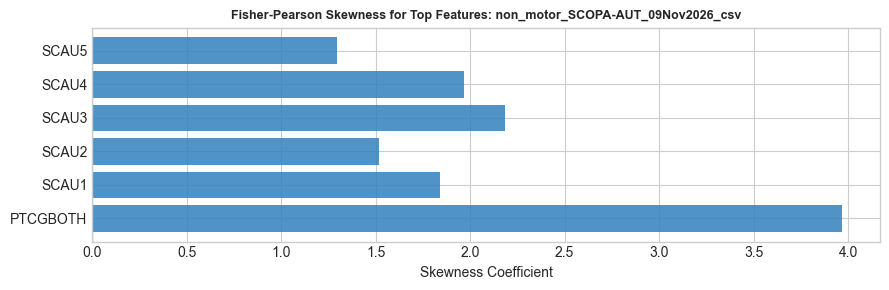

In [3]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "non_motor_SCOPA-AUT_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: non motor/SCOPA-AUT_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to non_motor_SCOPA-AUT_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in non_motor_SCOPA-AUT_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: non_motor_SCOPA-AUT_09Nov2026_csv", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `28` continuous analytical measurements
- **Excluded Features**: `16` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `19.4%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,680 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,016


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,19.42%,19.42%
1,PC2,8.31%,27.72%
2,PC3,6.98%,34.70%
3,PC4,5.17%,39.87%
4,PC5,4.64%,44.51%



Top PC1 Feature Loadings:


,feature_name,loading
0,SCAU8,0.2978
1,SCAU10,0.2905
2,SCAU5,0.2728
3,SCAU12,0.2697
4,SCAU9,0.2696


Scree & Eigenvector Loadings Plot:


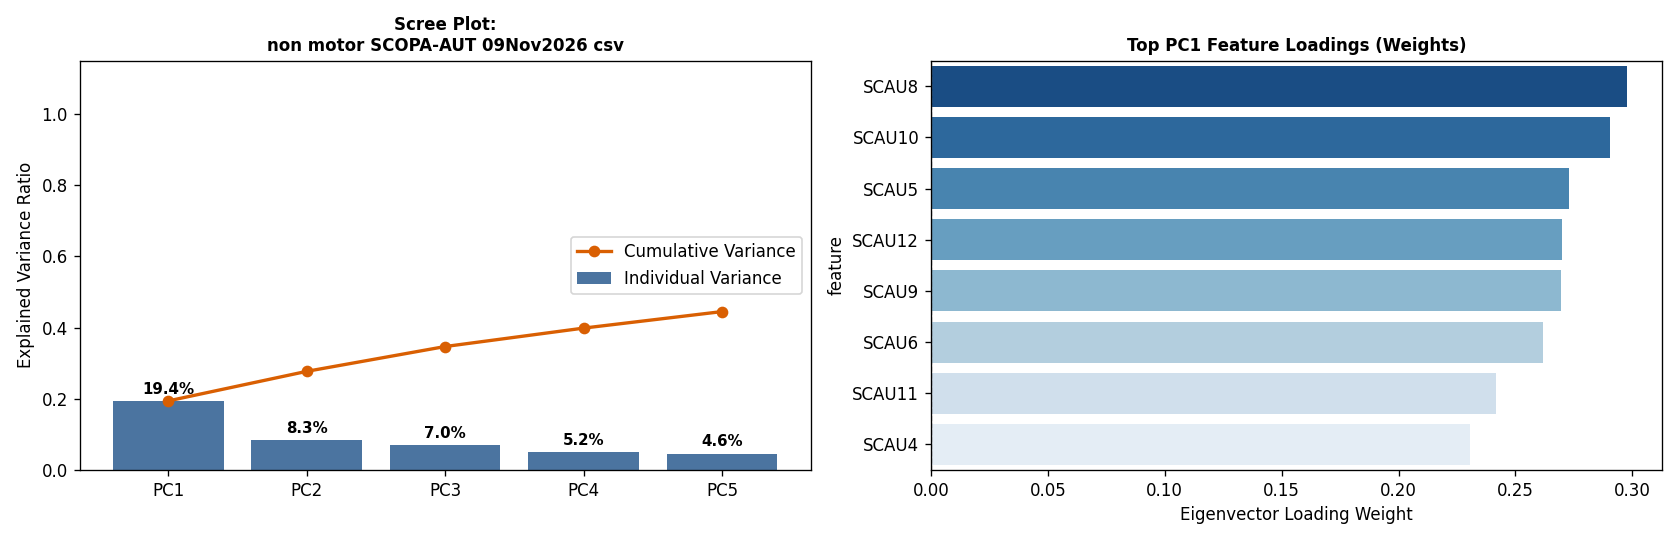

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


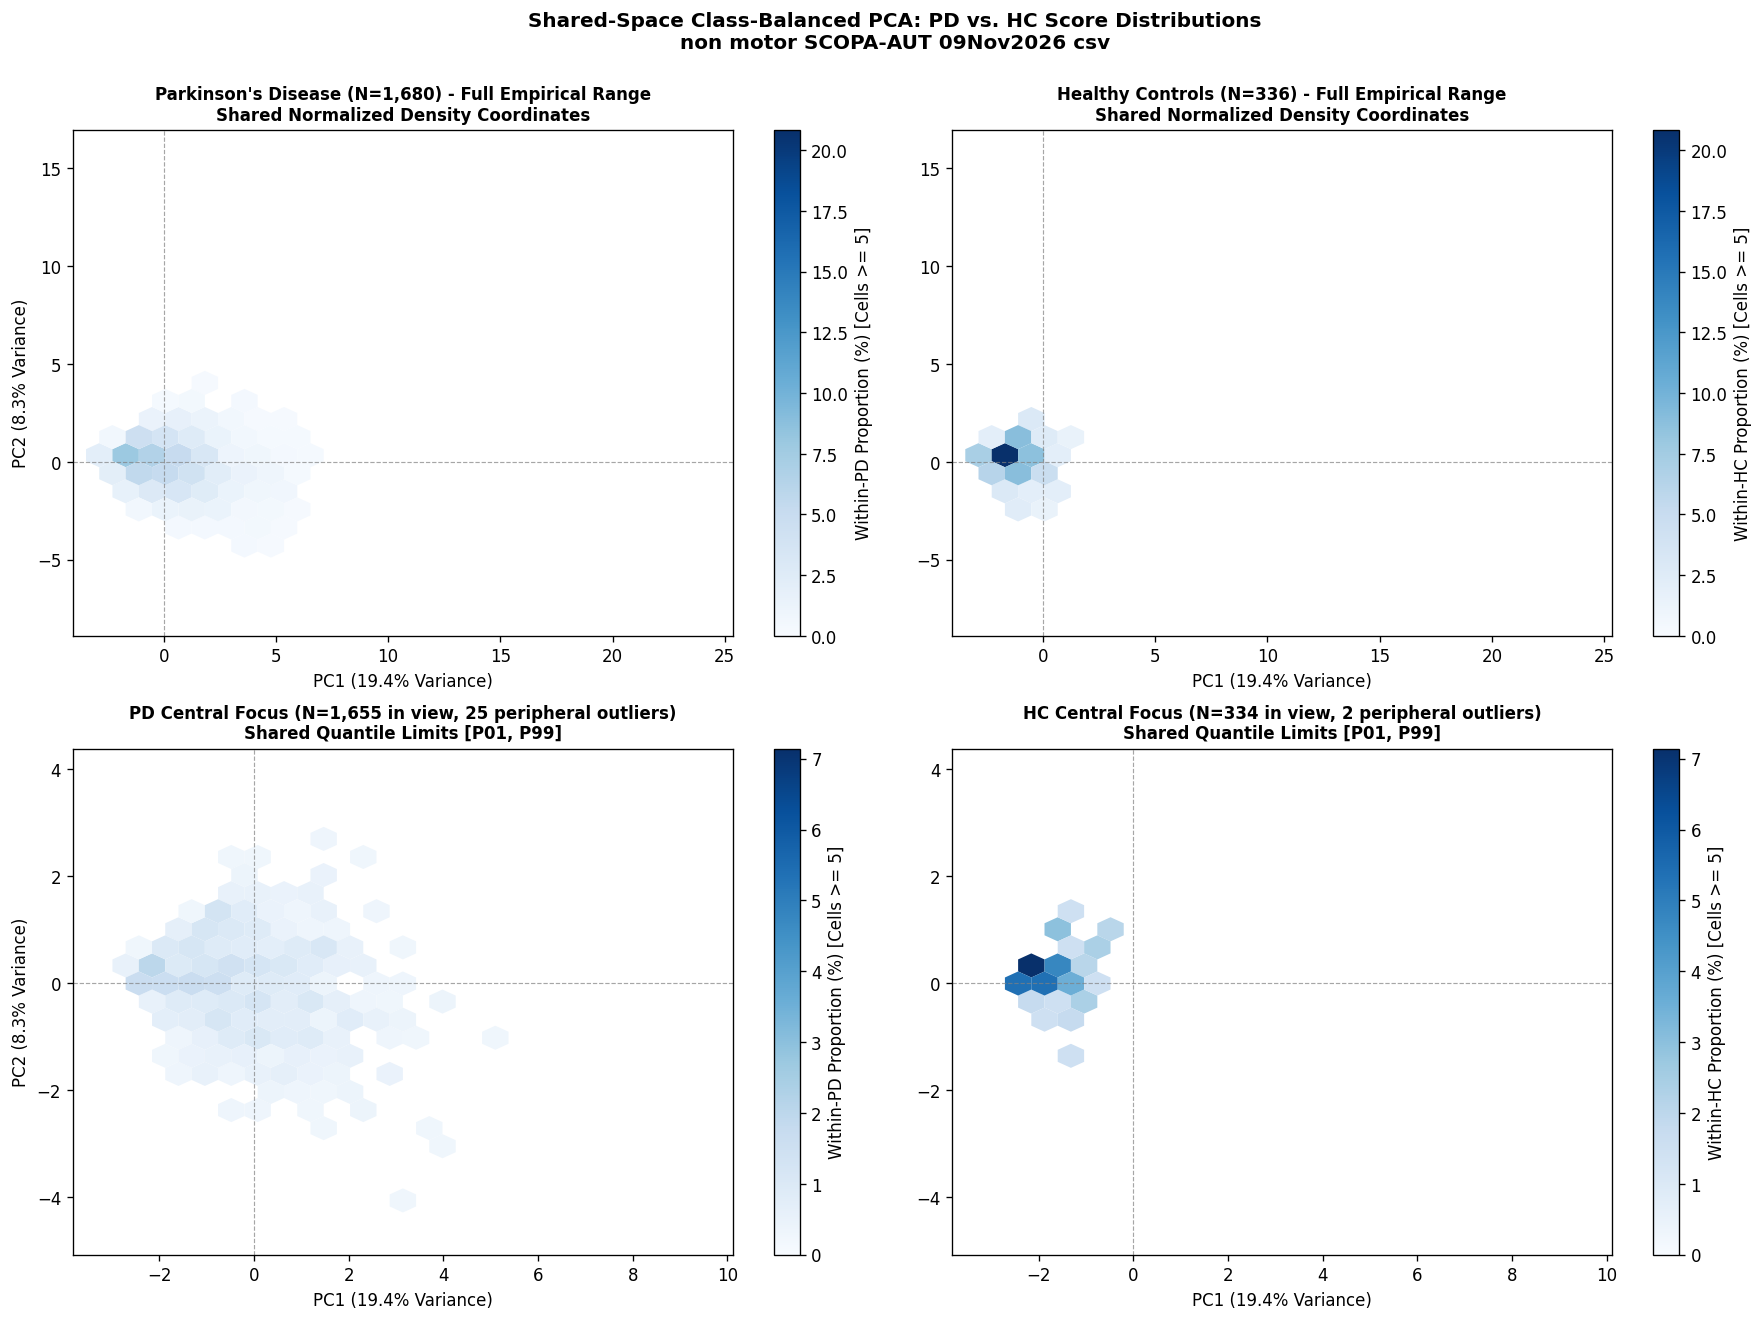

In [4]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/non_motor_SCOPA-AUT_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/non_motor_SCOPA-AUT_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.2. Unit: `REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026.csv` 
- **Unit Slug**: `sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv`
- **Source Path**: `sleep disorder/REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026.csv`
- **Committed Unit Artifact**: [`sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv.json`](../EDA/outputs/reports/units/sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `RBDSQ screens for dream-enactment behavior, nocturnal movements, and sleep disruption. REM Sleep Behavior Disorder (RBD) is the strongest clinical prodromal indicator of alpha-synucleinopathy.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: sleep disorder/REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 11,630 analyzed rows x 30 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 22,666 (5,343 participants)
  - PD Retained:  9,361 rows (1,680 participants)
  - HC Retained:  2,269 rows (336 participants)
  - Non-Target Excluded: 10,690 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  346 rows

Exact Variable Schema & Storage Types (30 columns):
Showing first 20 of 30 columns (complete schema committed to sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"11,630",Identifier
1,PATNO,int64,0,0.0%,"2,016",Identifier
2,EVENT_ID,object,0,0.0%,24,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,PTCGBOTH,float64,2,0.0%,3,Analytical Numeric Measurement
6,DRMVIVID,float64,0,0.0%,2,Identifier
7,DRMAGRAC,float64,2,0.0%,2,Analytical Numeric Measurement
8,DRMNOCTB,float64,19,0.2%,2,Analytical Numeric Measurement
9,SLPLMBMV,float64,4,0.0%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,21
Identifier,4
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 110 / 348,900 (0.03%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (21 total, top 8):


,name,missing_count,missing_percent,variable_role
26,CNSOTH,27,0.2%,Analytical Numeric Measurement
8,DRMNOCTB,19,0.2%,Analytical Numeric Measurement
10,SLPINJUR,7,0.1%,Analytical Numeric Measurement
13,DRMUMV,6,0.1%,Analytical Numeric Measurement
12,DRMFIGHT,5,0.0%,Analytical Numeric Measurement
22,NARCLPSY,4,0.0%,Analytical Numeric Measurement
23,DEPRS,3,0.0%,Analytical Numeric Measurement
9,SLPLMBMV,4,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"9,361"
1,HC,"2,269"



Numeric Summaries & Outlier Diagnostics (21 continuous/discrete features):
Showing top 10 of 21 features (full distribution profiles in sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PTCGBOTH,1.124,0.475,1.0,1.0,3.0,3.627,Strongly skewed (positive),766,679
1,DRMAGRAC,0.270,0.444,0.0,0.0,1.0,1.038,Strongly skewed (positive),0,0
2,DRMNOCTB,0.275,0.446,0.0,0.0,1.0,1.010,Strongly skewed (positive),0,0
3,SLPLMBMV,0.323,0.468,0.0,0.0,1.0,0.755,Moderately skewed (positive),0,0
4,SLPINJUR,0.144,0.351,0.0,0.0,1.0,2.030,Strongly skewed (positive),"1,672",0
5,DRMVERBL,0.367,0.482,0.0,0.0,1.0,0.552,Moderately skewed (positive),0,0
6,DRMFIGHT,0.293,0.455,0.0,0.0,1.0,0.909,Moderately skewed (positive),0,0
7,DRMUMV,0.145,0.352,0.0,0.0,1.0,2.017,Strongly skewed (positive),"1,685",0
8,DRMOBJFL,0.093,0.291,0.0,0.0,1.0,2.800,Strongly skewed (positive),"1,083","1,083"
9,MVAWAKEN,0.240,0.427,0.0,0.0,1.0,1.220,Strongly skewed (positive),"2,786",0


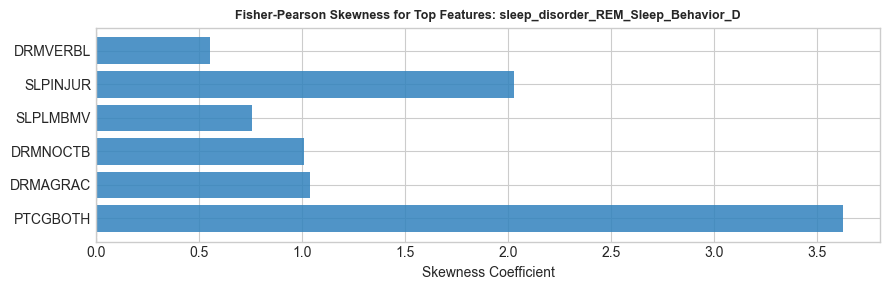

In [5]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: sleep disorder/REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: sleep_disorder_REM_Sleep_Behavior_D", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `21` continuous analytical measurements
- **Excluded Features**: `9` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `21.1%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,680 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,016


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,21.08%,21.08%
1,PC2,6.60%,27.68%
2,PC3,6.51%,34.19%
3,PC4,6.12%,40.31%
4,PC5,5.24%,45.55%



Top PC1 Feature Loadings:


,feature_name,loading
0,DRMFIGHT,0.3685
1,DRMUMV,0.3285
2,MVAWAKEN,0.3278
3,SLPINJUR,0.3130
4,DRMVERBL,0.3041


Scree & Eigenvector Loadings Plot:


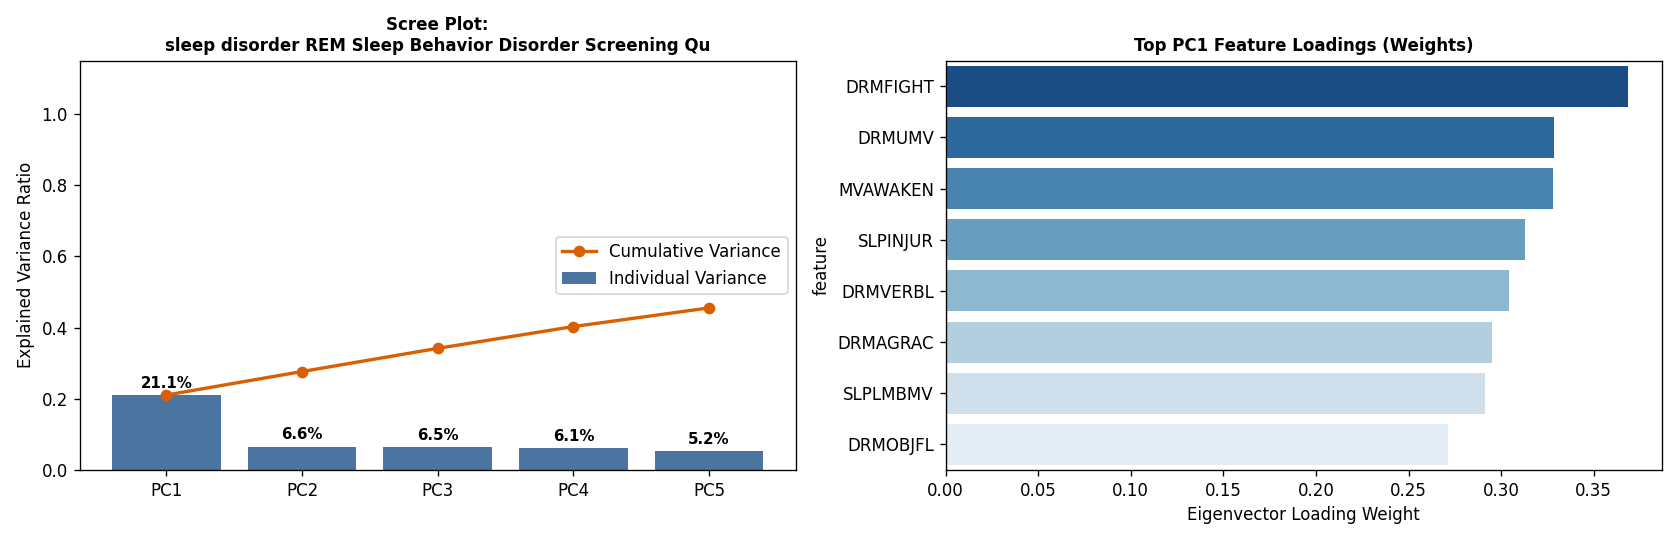

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


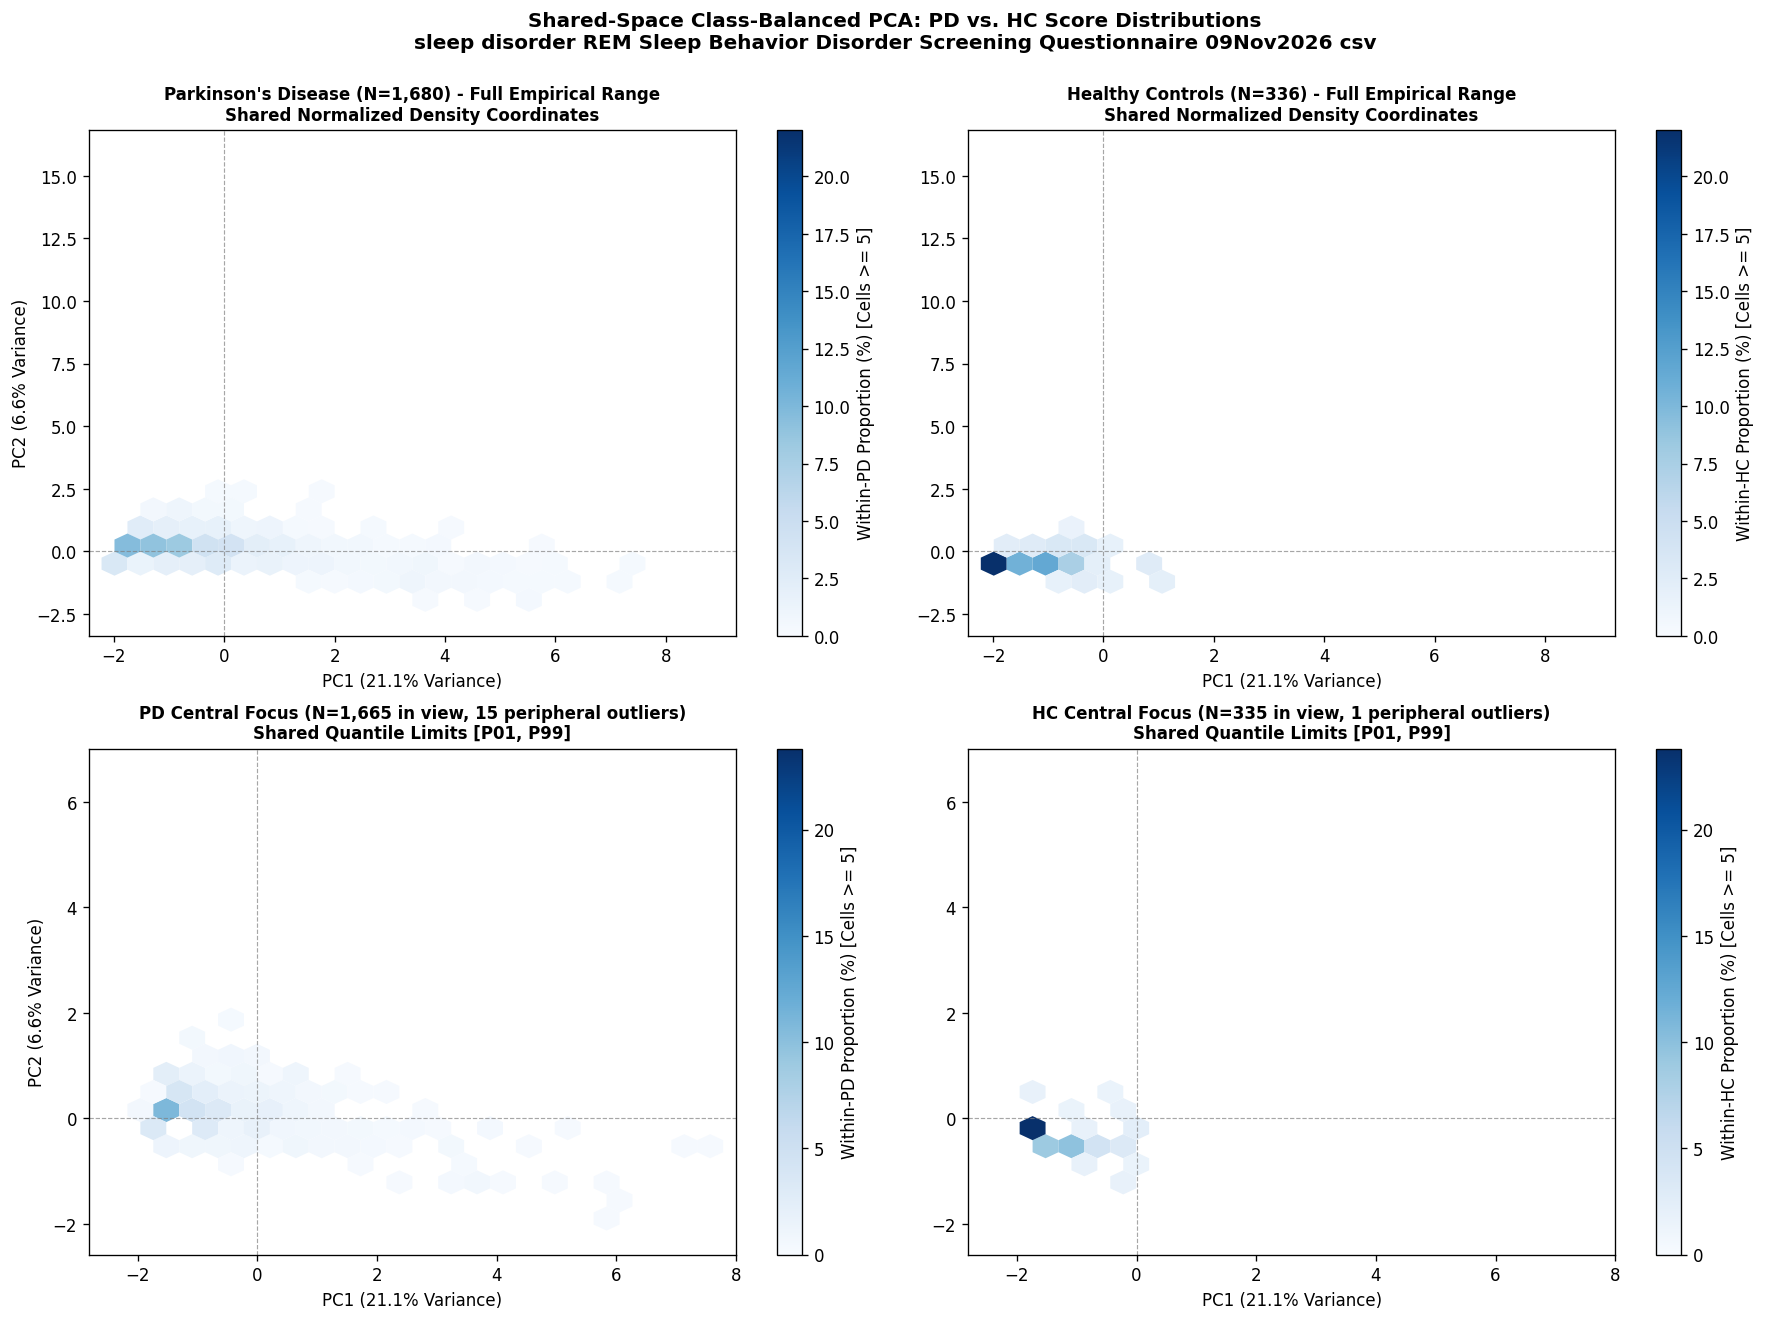

In [6]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/sleep_disorder_REM_Sleep_Behavior_Disorder_Screening_Questionnaire_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.3. Unit: `Epworth_Sleepiness_Scale_09Nov2026.csv` 
- **Unit Slug**: `sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv`
- **Source Path**: `sleep disorder/Epworth_Sleepiness_Scale_09Nov2026.csv`
- **Committed Unit Artifact**: [`sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv.json`](../EDA/outputs/reports/units/sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Standardized 8-scenario evaluation of daytime sleepiness and unintended sleep episodes.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: sleep disorder/Epworth_Sleepiness_Scale_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 11,623 analyzed rows x 17 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 22,655 (5,341 participants)
  - PD Retained:  9,355 rows (1,680 participants)
  - HC Retained:  2,268 rows (336 participants)
  - Non-Target Excluded: 10,688 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  344 rows

Exact Variable Schema & Storage Types (17 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"11,623",Identifier
1,PATNO,int64,0,0.0%,"2,016",Identifier
2,EVENT_ID,object,0,0.0%,25,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,PTCGBOTH,float64,1,0.0%,3,Analytical Numeric Measurement
6,ESS1,int64,0,0.0%,4,Analytical Numeric Measurement
7,ESS2,float64,2,0.0%,4,Analytical Numeric Measurement
8,ESS3,float64,1,0.0%,4,Analytical Numeric Measurement
9,ESS4,float64,0,0.0%,4,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,9
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 20 / 197,591 (0.01%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (7 total, top 8):


,name,missing_count,missing_percent,variable_role
13,ESS8,11,0.1%,Analytical Numeric Measurement
10,ESS5,2,0.0%,Analytical Numeric Measurement
7,ESS2,2,0.0%,Analytical Numeric Measurement
12,ESS7,2,0.0%,Analytical Numeric Measurement
5,PTCGBOTH,1,0.0%,Analytical Numeric Measurement
8,ESS3,1,0.0%,Analytical Numeric Measurement
11,ESS6,1,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"9,355"
1,HC,"2,268"



Numeric Summaries & Outlier Diagnostics (9 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PTCGBOTH,1.111,0.451,1.0,1.0,3.0,3.875,Strongly skewed (positive),686,608
1,ESS1,1.101,0.898,0.0,1.0,3.0,0.538,Moderately skewed (positive),0,0
2,ESS2,1.232,0.890,0.0,1.0,3.0,0.362,Approximately symmetric,0,0
3,ESS3,0.507,0.734,0.0,0.0,3.0,1.398,Strongly skewed (positive),251,251
4,ESS4,0.825,0.917,0.0,1.0,3.0,0.904,Moderately skewed (positive),825,0
5,ESS5,1.839,1.013,0.0,2.0,3.0,-0.310,Approximately symmetric,0,0
6,ESS6,0.138,0.418,0.0,0.0,3.0,3.478,Strongly skewed (positive),"1,327",231
7,ESS7,0.708,0.842,0.0,1.0,3.0,1.034,Strongly skewed (positive),510,0
8,ESS8,0.150,0.452,0.0,0.0,3.0,3.547,Strongly skewed (positive),"1,382",280


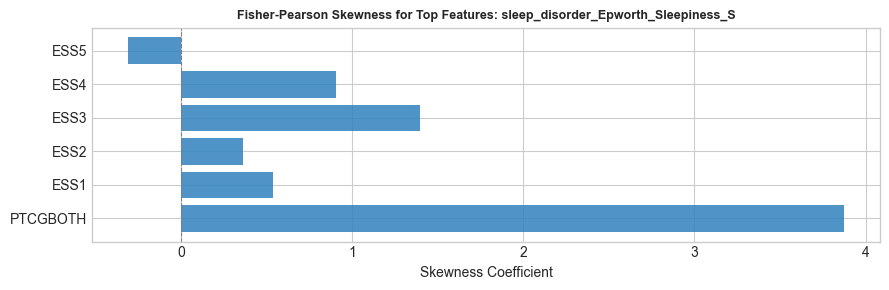

In [7]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: sleep disorder/Epworth_Sleepiness_Scale_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: sleep_disorder_Epworth_Sleepiness_S", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `8` continuous analytical measurements
- **Excluded Features**: `9` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `41.4%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,680 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,016


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,41.37%,41.37%
1,PC2,12.44%,53.81%
2,PC3,10.32%,64.13%
3,PC4,9.12%,73.25%
4,PC5,8.32%,81.56%



Top PC1 Feature Loadings:


,feature_name,loading
0,ESS3,0.4042
1,ESS1,0.3984
2,ESS7,0.3816
3,ESS4,0.3700
4,ESS2,0.3664


Scree & Eigenvector Loadings Plot:


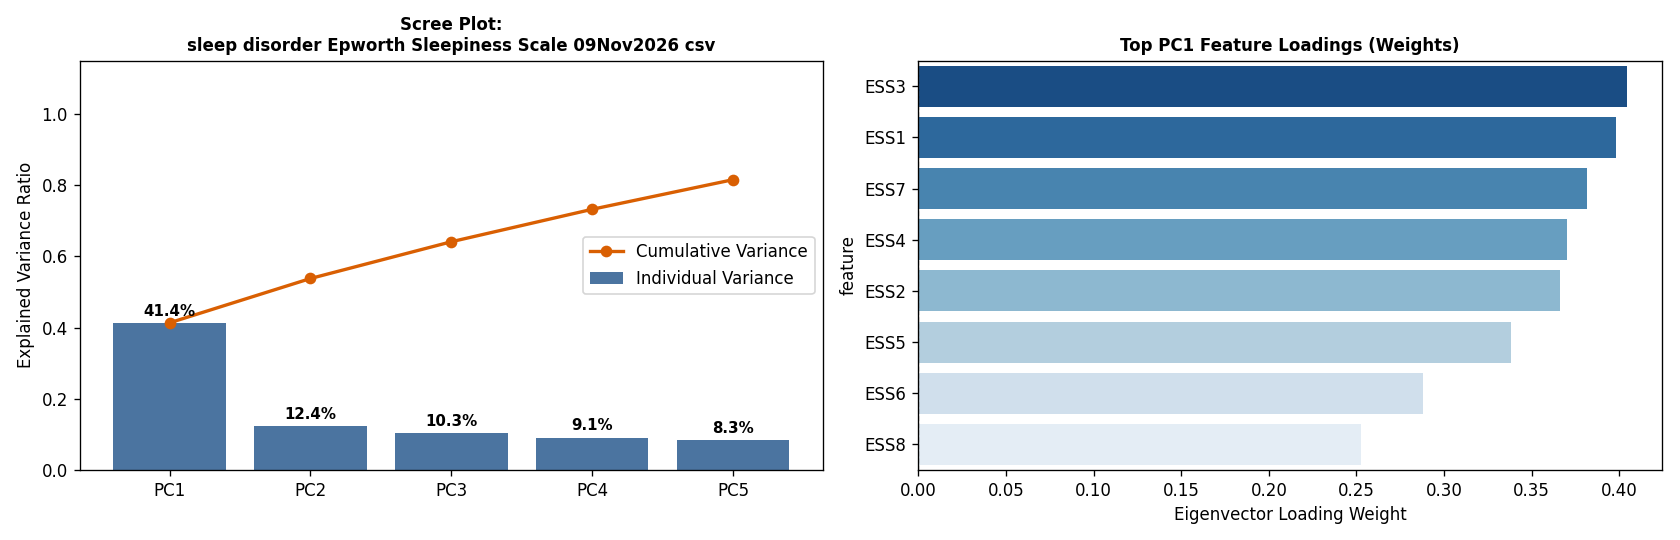

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


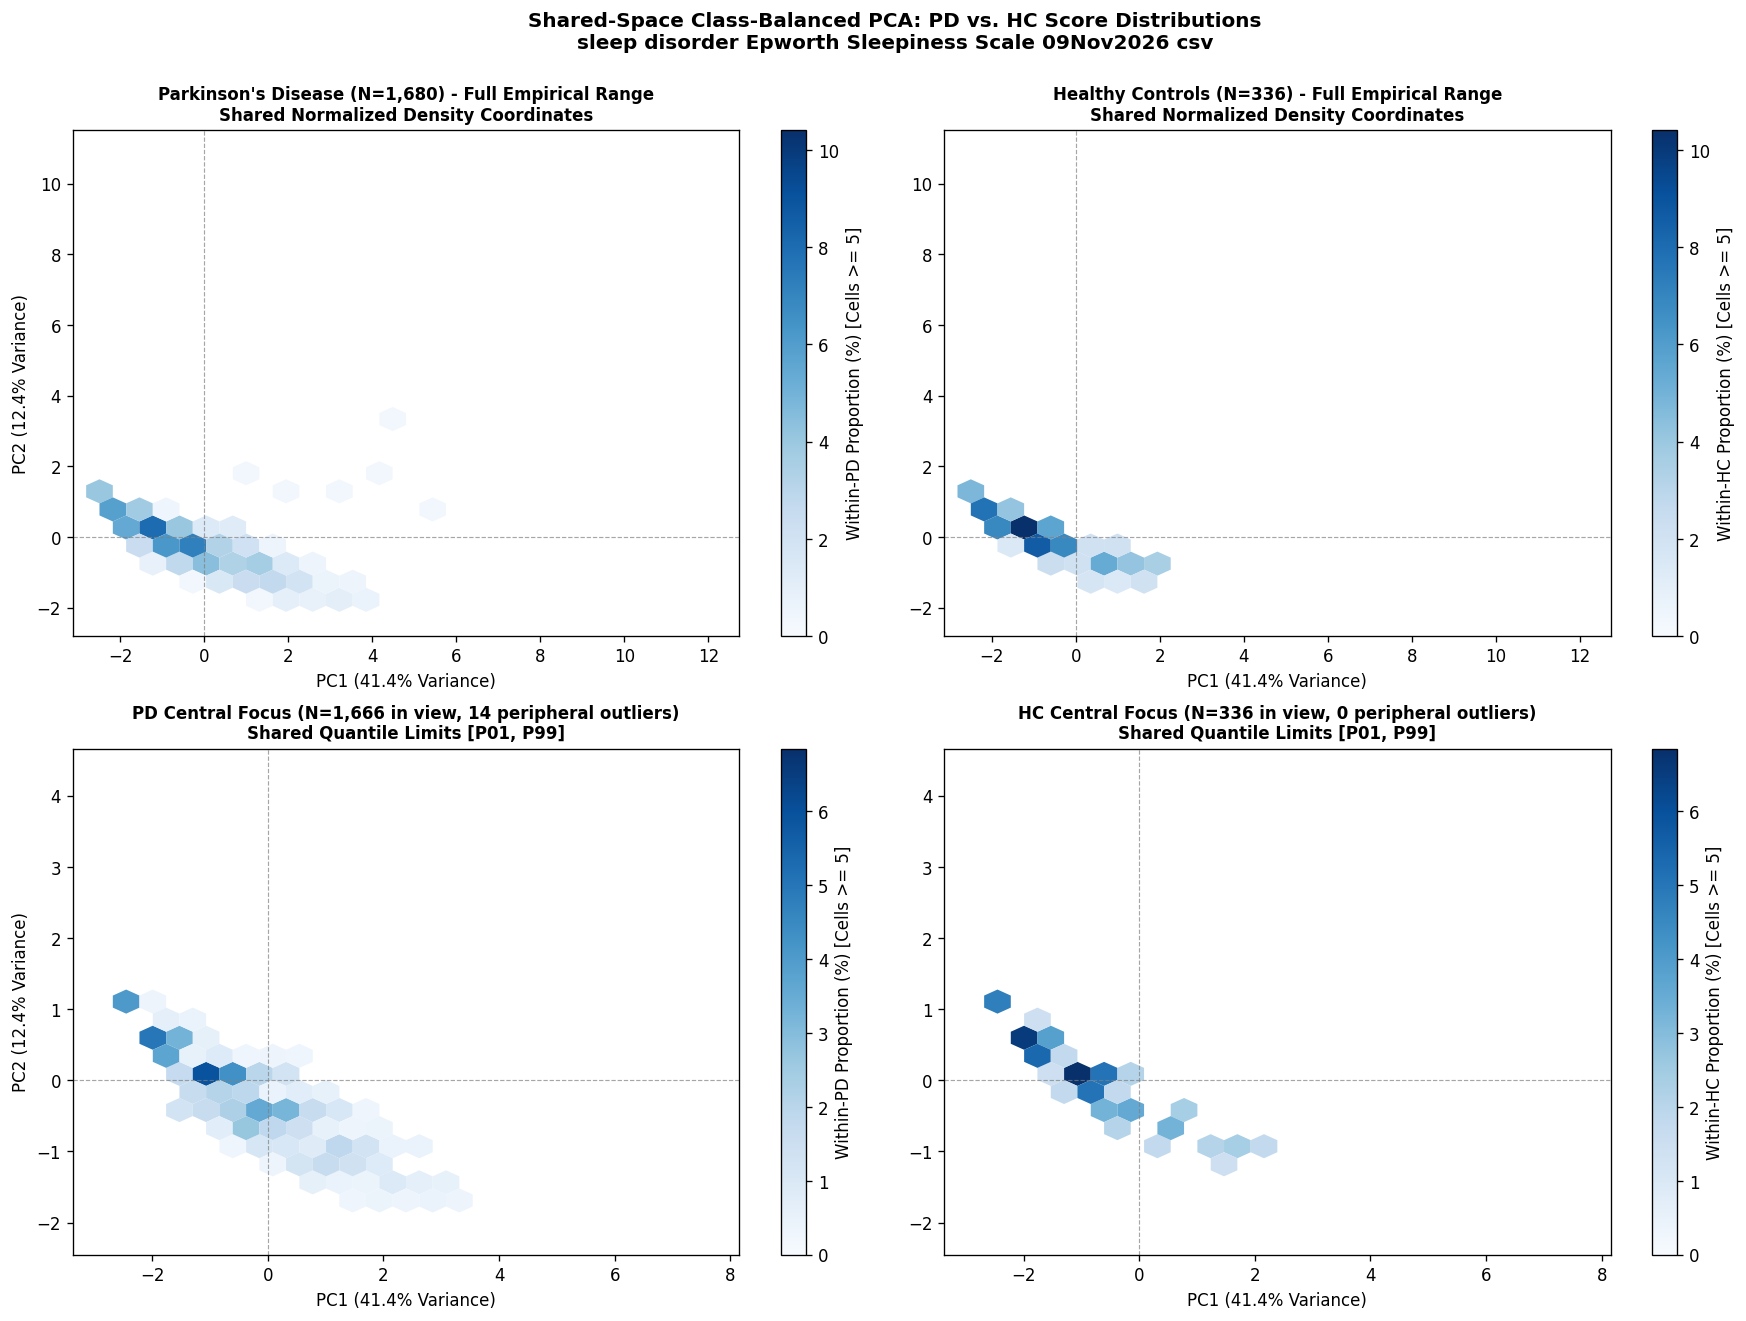

In [8]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/sleep_disorder_Epworth_Sleepiness_Scale_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.4. Unit: `Geriatric_Depression_Scale__Short_Version__09Nov2026.csv` 
- **Unit Slug**: `neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv`
- **Source Path**: `neurobehavioral/Geriatric_Depression_Scale__Short_Version__09Nov2026.csv`
- **Committed Unit Artifact**: [`neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv.json`](../EDA/outputs/reports/units/neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `15-item short-form GDS assessing affective changes, depressive burden, and emotional well-being.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neurobehavioral/Geriatric_Depression_Scale__Short_Version__09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 11,594 analyzed rows x 23 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 22,919 (5,468 participants)
  - PD Retained:  9,326 rows (1,680 participants)
  - HC Retained:  2,268 rows (336 participants)
  - Non-Target Excluded: 10,851 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  474 rows

Exact Variable Schema & Storage Types (23 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"11,594",Identifier
1,PATNO,int64,0,0.0%,"2,016",Identifier
2,EVENT_ID,object,0,0.0%,24,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,GDSSATIS,float64,4,0.0%,2,Analytical Numeric Measurement
6,GDSDROPD,float64,4,0.0%,2,Analytical Numeric Measurement
7,GDSEMPTY,float64,2,0.0%,2,Analytical Numeric Measurement
8,GDSBORED,float64,3,0.0%,2,Analytical Numeric Measurement
9,GDSGSPIR,float64,4,0.0%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,15
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 61 / 266,662 (0.02%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (15 total, top 8):


,name,missing_count,missing_percent,variable_role
15,GDSALIVE,7,0.1%,Analytical Numeric Measurement
16,GDSWRTLS,7,0.1%,Analytical Numeric Measurement
11,GDSHAPPY,6,0.1%,Analytical Numeric Measurement
13,GDSHOME,5,0.0%,Analytical Numeric Measurement
9,GDSGSPIR,4,0.0%,Analytical Numeric Measurement
6,GDSDROPD,4,0.0%,Analytical Numeric Measurement
5,GDSSATIS,4,0.0%,Analytical Numeric Measurement
18,GDSHOPLS,3,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"9,326"
1,HC,"2,268"



Numeric Summaries & Outlier Diagnostics (15 continuous/discrete features):
Showing top 10 of 15 features (full distribution profiles in neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,GDSSATIS,0.898,0.302,0.0,1.0,1.0,-2.637,Strongly skewed (negative),"1,178",0
1,GDSDROPD,0.224,0.417,0.0,0.0,1.0,1.324,Strongly skewed (positive),"2,597",0
2,GDSEMPTY,0.071,0.257,0.0,0.0,1.0,3.336,Strongly skewed (positive),825,825
3,GDSBORED,0.149,0.356,0.0,0.0,1.0,1.975,Strongly skewed (positive),"1,724",0
4,GDSGSPIR,0.894,0.307,0.0,1.0,1.0,-2.565,Strongly skewed (negative),"1,225",0
5,GDSAFRAD,0.163,0.370,0.0,0.0,1.0,1.823,Strongly skewed (positive),"1,891",0
6,GDSHAPPY,0.857,0.351,0.0,1.0,1.0,-2.035,Strongly skewed (negative),"1,662",0
7,GDSHLPLS,0.108,0.311,0.0,0.0,1.0,2.519,Strongly skewed (positive),"1,257",0
8,GDSHOME,0.339,0.473,0.0,0.0,1.0,0.682,Moderately skewed (positive),0,0
9,GDSMEMRY,0.241,0.428,0.0,0.0,1.0,1.212,Strongly skewed (positive),"2,792",0


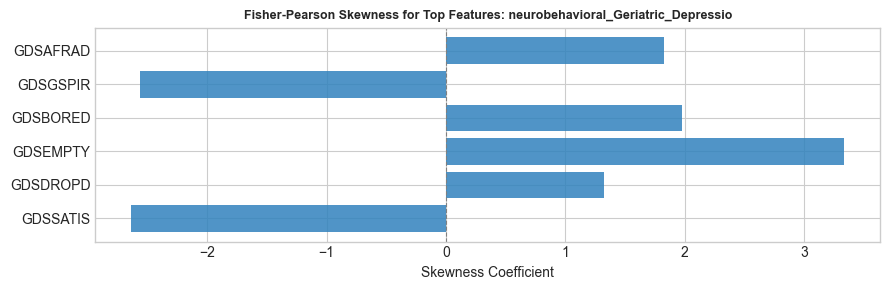

In [9]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neurobehavioral/Geriatric_Depression_Scale__Short_Version__09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neurobehavioral_Geriatric_Depressio", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `15` continuous analytical measurements
- **Excluded Features**: `8` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `34.6%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,680 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,016


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,34.61%,34.61%
1,PC2,8.67%,43.28%
2,PC3,7.16%,50.44%
3,PC4,6.10%,56.54%
4,PC5,5.78%,62.32%



Top PC1 Feature Loadings:


,feature_name,loading
0,GDSHLPLS,0.3141
1,GDSSATIS,-0.3070
2,GDSWRTLS,0.3005
3,GDSGSPIR,-0.2882
4,GDSEMPTY,0.2872


Scree & Eigenvector Loadings Plot:


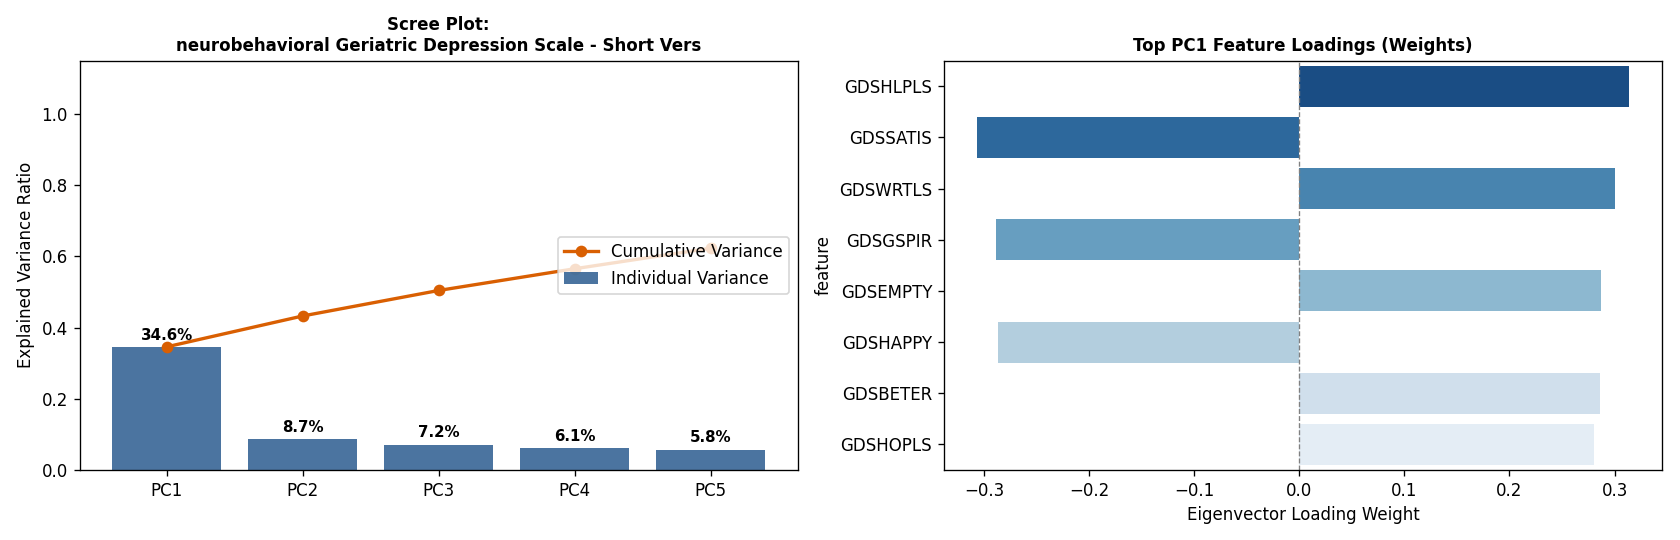

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


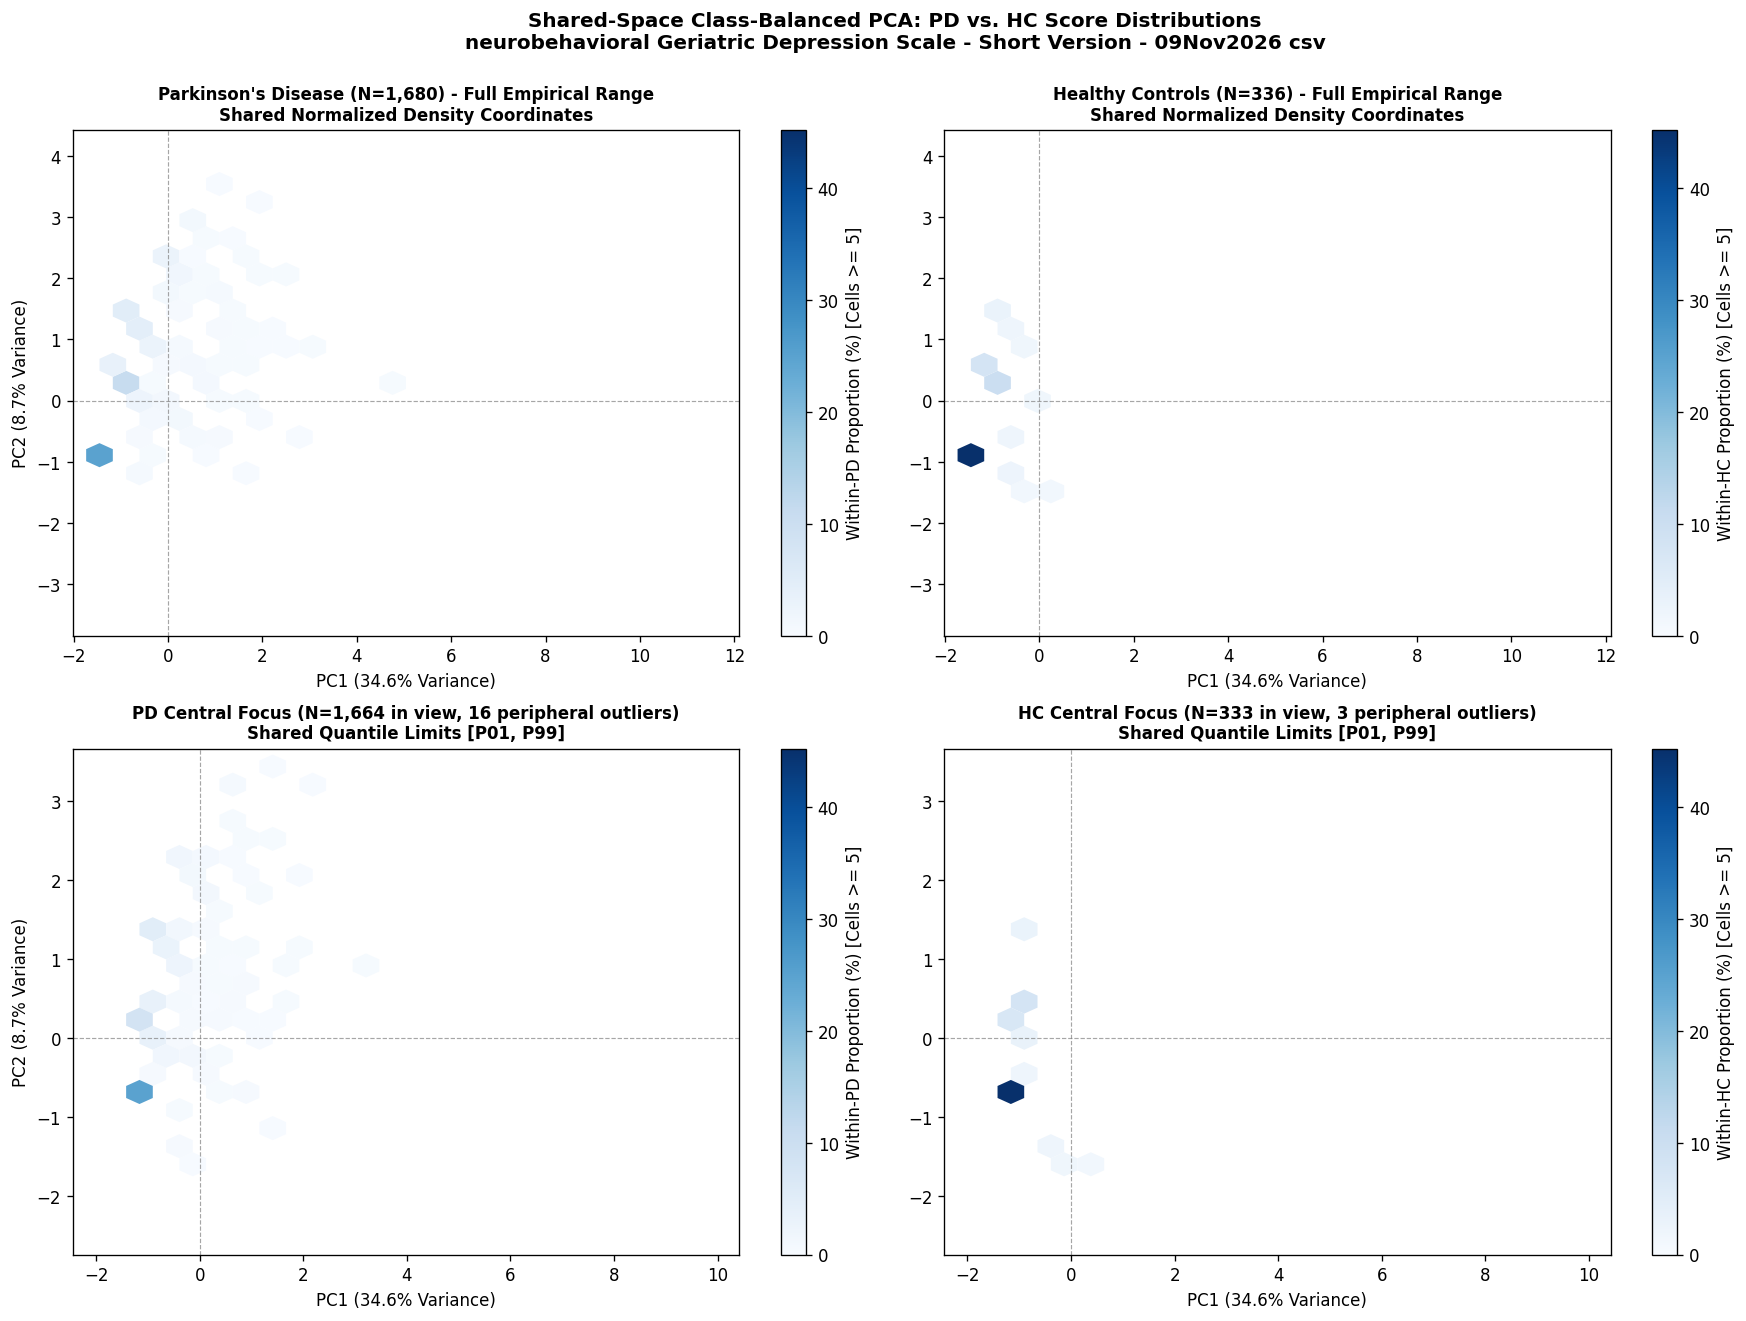

In [10]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neurobehavioral_Geriatric_Depression_Scale__Short_Version__09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.5. Unit: `State-Trait_Anxiety_Inventory_for_Adults_09Nov2026.csv` 
- **Unit Slug**: `neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv`
- **Source Path**: `neurobehavioral/State-Trait_Anxiety_Inventory_for_Adults_09Nov2026.csv`
- **Committed Unit Artifact**: [`neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv.json`](../EDA/outputs/reports/units/neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Differentiates acute situational anxiety (State) from baseline personality anxiety predisposition (Trait).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neurobehavioral/State-Trait_Anxiety_Inventory_for_Adults_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 11,579 analyzed rows x 48 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 22,888 (5,463 participants)
  - PD Retained:  9,310 rows (1,679 participants)
  - HC Retained:  2,269 rows (336 participants)
  - Non-Target Excluded: 10,838 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  471 rows

Exact Variable Schema & Storage Types (48 columns):
Showing first 20 of 48 columns (complete schema committed to neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"11,579",Identifier
1,PATNO,int64,0,0.0%,"2,015",Identifier
2,EVENT_ID,object,0,0.0%,24,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,STAIAD1,float64,3,0.0%,4,Analytical Numeric Measurement
6,STAIAD2,float64,3,0.0%,4,Analytical Numeric Measurement
7,STAIAD3,float64,3,0.0%,4,Analytical Numeric Measurement
8,STAIAD4,float64,7,0.1%,4,Analytical Numeric Measurement
9,STAIAD5,float64,5,0.0%,4,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,40
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 338 / 555,792 (0.06%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (40 total, top 8):


,name,missing_count,missing_percent,variable_role
38,STAIAD34,15,0.1%,Analytical Numeric Measurement
40,STAIAD36,14,0.1%,Analytical Numeric Measurement
29,STAIAD25,13,0.1%,Analytical Numeric Measurement
44,STAIAD40,13,0.1%,Analytical Numeric Measurement
37,STAIAD33,12,0.1%,Analytical Numeric Measurement
26,STAIAD22,11,0.1%,Analytical Numeric Measurement
28,STAIAD24,11,0.1%,Analytical Numeric Measurement
27,STAIAD23,11,0.1%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"9,310"
1,HC,"2,269"



Numeric Summaries & Outlier Diagnostics (40 continuous/discrete features):
Showing top 10 of 40 features (full distribution profiles in neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,STAIAD1,3.330,0.780,1.0,4.0,4.0,-0.894,Moderately skewed (negative),224,0
1,STAIAD2,3.503,0.746,1.0,4.0,4.0,-1.442,Strongly skewed (negative),260,260
2,STAIAD3,1.624,0.784,1.0,1.0,4.0,1.131,Strongly skewed (positive),337,337
3,STAIAD4,1.446,0.735,1.0,1.0,4.0,1.666,Strongly skewed (positive),285,285
4,STAIAD5,3.210,0.900,1.0,3.0,4.0,-0.875,Moderately skewed (negative),632,0
5,STAIAD6,1.270,0.606,1.0,1.0,4.0,2.497,Strongly skewed (positive),"2,325",179
6,STAIAD7,1.491,0.773,1.0,1.0,4.0,1.598,Strongly skewed (positive),391,391
7,STAIAD8,3.247,0.857,1.0,3.0,4.0,-0.904,Moderately skewed (negative),494,0
8,STAIAD9,1.225,0.563,1.0,1.0,4.0,2.867,Strongly skewed (positive),"1,937",502
9,STAIAD10,3.346,0.815,1.0,4.0,4.0,-1.054,Strongly skewed (negative),357,0


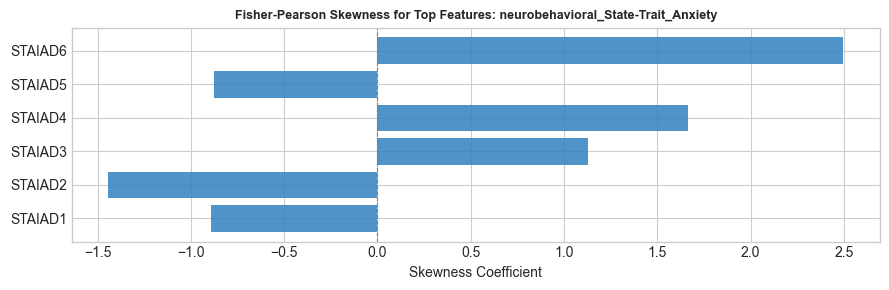

In [11]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neurobehavioral/State-Trait_Anxiety_Inventory_for_Adults_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neurobehavioral_State-Trait_Anxiety", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `40` continuous analytical measurements
- **Excluded Features**: `8` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `35.6%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,679 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,015


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,35.63%,35.63%
1,PC2,7.13%,42.75%
2,PC3,5.53%,48.28%
3,PC4,3.56%,51.84%
4,PC5,2.81%,54.65%



Top PC1 Feature Loadings:


,feature_name,loading
0,STAIAD36,0.1994
1,STAIAD27,0.1933
2,STAIAD16,0.1931
3,STAIAD33,0.1913
4,STAIAD8,0.1884


Scree & Eigenvector Loadings Plot:


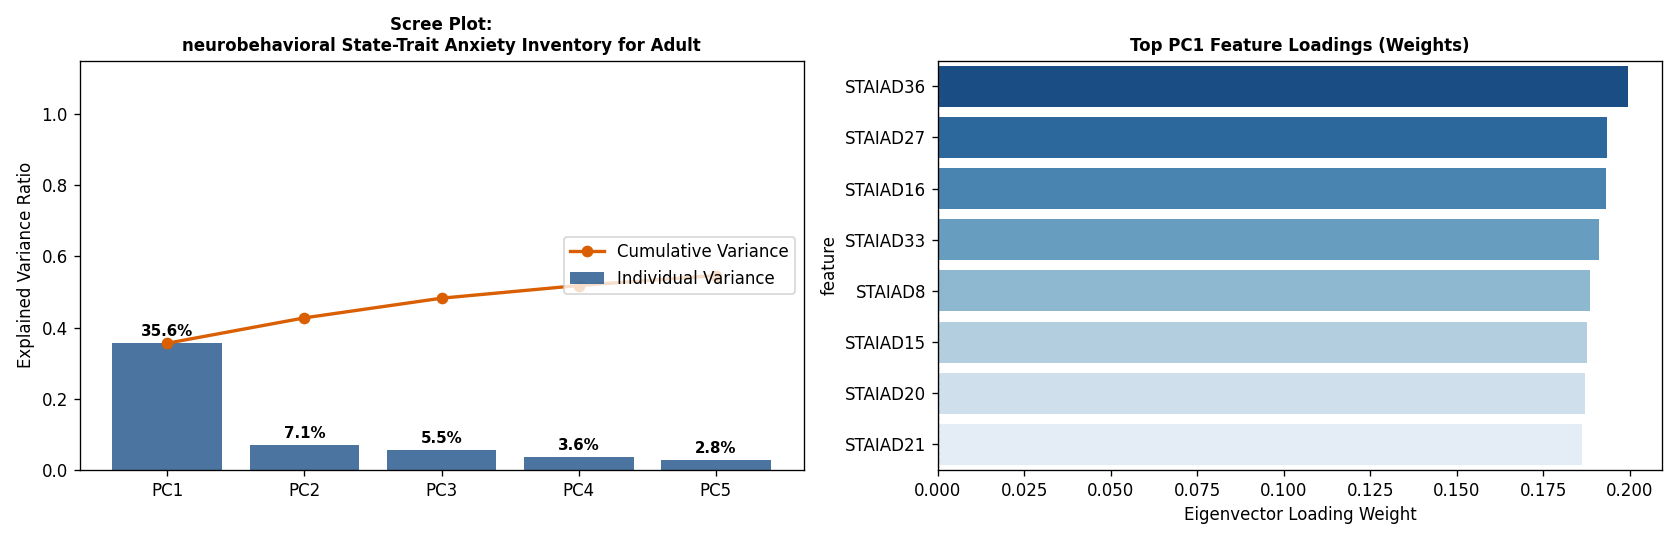

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


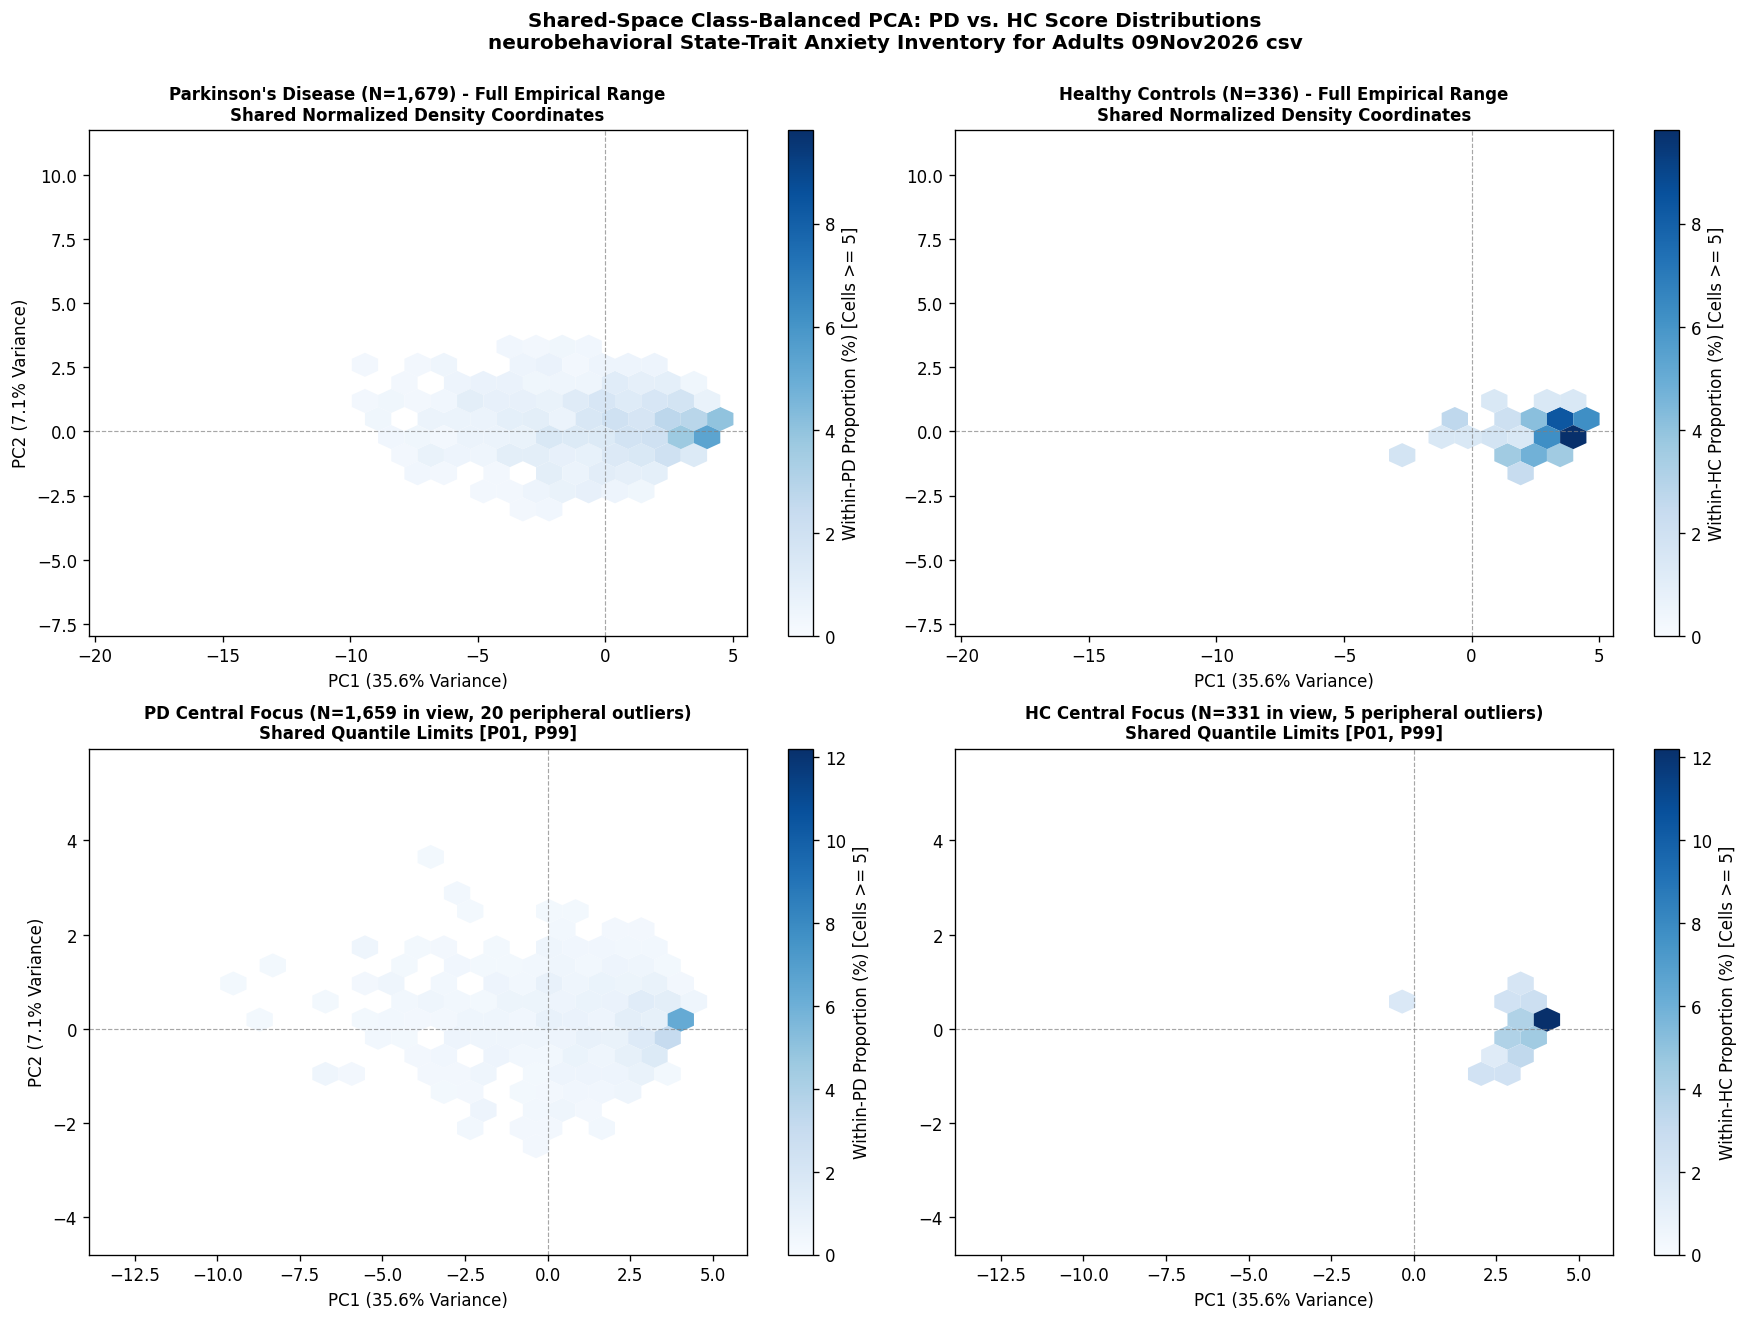

In [12]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neurobehavioral_State-Trait_Anxiety_Inventory_for_Adults_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.6. Unit: `QUIP-Current-Short_09Nov2026.csv` 
- **Unit Slug**: `neurobehavioral_QUIP-Current-Short_09Nov2026_csv`
- **Source Path**: `neurobehavioral/QUIP-Current-Short_09Nov2026.csv`
- **Committed Unit Artifact**: [`neurobehavioral_QUIP-Current-Short_09Nov2026_csv.json`](../EDA/outputs/reports/units/neurobehavioral_QUIP-Current-Short_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Questionnaire for Impulsive-Compulsive Disorders in Parkinson's Disease (compulsive gambling, hypersexuality, shopping, binge eating, punding).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neurobehavioral/QUIP-Current-Short_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 11,595 analyzed rows x 22 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 22,593 (5,334 participants)
  - PD Retained:  9,327 rows (1,680 participants)
  - HC Retained:  2,268 rows (336 participants)
  - Non-Target Excluded: 10,658 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  340 rows

Exact Variable Schema & Storage Types (22 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"11,595",Identifier
1,PATNO,int64,0,0.0%,"2,016",Identifier
2,EVENT_ID,object,0,0.0%,24,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,PTINBOTH,float64,1,0.0%,3,Analytical Numeric Measurement
6,TMGAMBLE,float64,2,0.0%,2,Analytical Numeric Measurement
7,CNTRLGMB,float64,10,0.1%,2,Analytical Numeric Measurement
8,TMSEX,float64,12,0.1%,2,Demographic / Covariate
9,CNTRLSEX,float64,18,0.2%,2,Demographic / Covariate



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,12
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Demographic / Covariate,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 74 / 255,090 (0.03%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (14 total, top 8):


,name,missing_count,missing_percent,variable_role
9,CNTRLSEX,18,0.2%,Demographic / Covariate
8,TMSEX,12,0.1%,Demographic / Covariate
7,CNTRLGMB,10,0.1%,Analytical Numeric Measurement
11,CNTRLBUY,8,0.1%,Analytical Numeric Measurement
12,TMEAT,3,0.0%,Analytical Numeric Measurement
10,TMBUY,4,0.0%,Analytical Numeric Measurement
13,CNTRLEAT,4,0.0%,Analytical Numeric Measurement
16,TMTRWD,4,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"9,327"
1,HC,"2,268"



Numeric Summaries & Outlier Diagnostics (14 continuous/discrete features):
Showing top 10 of 14 features (full distribution profiles in neurobehavioral_QUIP-Current-Short_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PTINBOTH,1.104,0.439,1.0,1.0,3.0,4.029,Strongly skewed (positive),632,577
1,TMGAMBLE,0.012,0.110,0.0,0.0,1.0,8.870,Strongly skewed (positive),142,142
2,CNTRLGMB,0.007,0.086,0.0,0.0,1.0,11.478,Strongly skewed (positive),86,86
3,TMSEX,0.026,0.160,0.0,0.0,1.0,5.907,Strongly skewed (positive),306,306
4,CNTRLSEX,0.037,0.188,0.0,0.0,1.0,4.941,Strongly skewed (positive),423,423
5,TMBUY,0.037,0.188,0.0,0.0,1.0,4.918,Strongly skewed (positive),427,427
6,CNTRLBUY,0.011,0.106,0.0,0.0,1.0,9.246,Strongly skewed (positive),131,131
7,TMEAT,0.070,0.255,0.0,0.0,1.0,3.367,Strongly skewed (positive),813,813
8,CNTRLEAT,0.043,0.202,0.0,0.0,1.0,4.534,Strongly skewed (positive),493,493
9,TMTORACT,0.094,0.291,0.0,0.0,1.0,2.793,Strongly skewed (positive),"1,084","1,084"


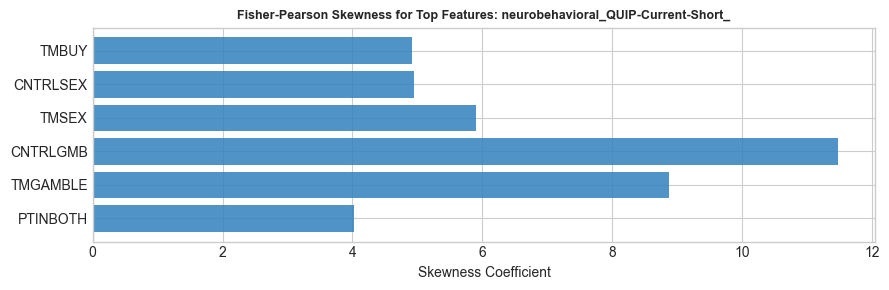

In [13]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neurobehavioral_QUIP-Current-Short_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neurobehavioral/QUIP-Current-Short_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neurobehavioral_QUIP-Current-Short_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neurobehavioral_QUIP-Current-Short_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neurobehavioral_QUIP-Current-Short_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `13` continuous analytical measurements
- **Excluded Features**: `9` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `17.6%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,680 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,016


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,17.59%,17.59%
1,PC2,14.56%,32.15%
2,PC3,11.65%,43.80%
3,PC4,10.27%,54.07%
4,PC5,8.20%,62.27%



Top PC1 Feature Loadings:


,feature_name,loading
0,TMDISMED,0.3390
1,TMBUY,-0.3358
2,CNTRLDSM,0.3300
3,TMSEX,-0.3085
4,TMEAT,-0.3007


Scree & Eigenvector Loadings Plot:


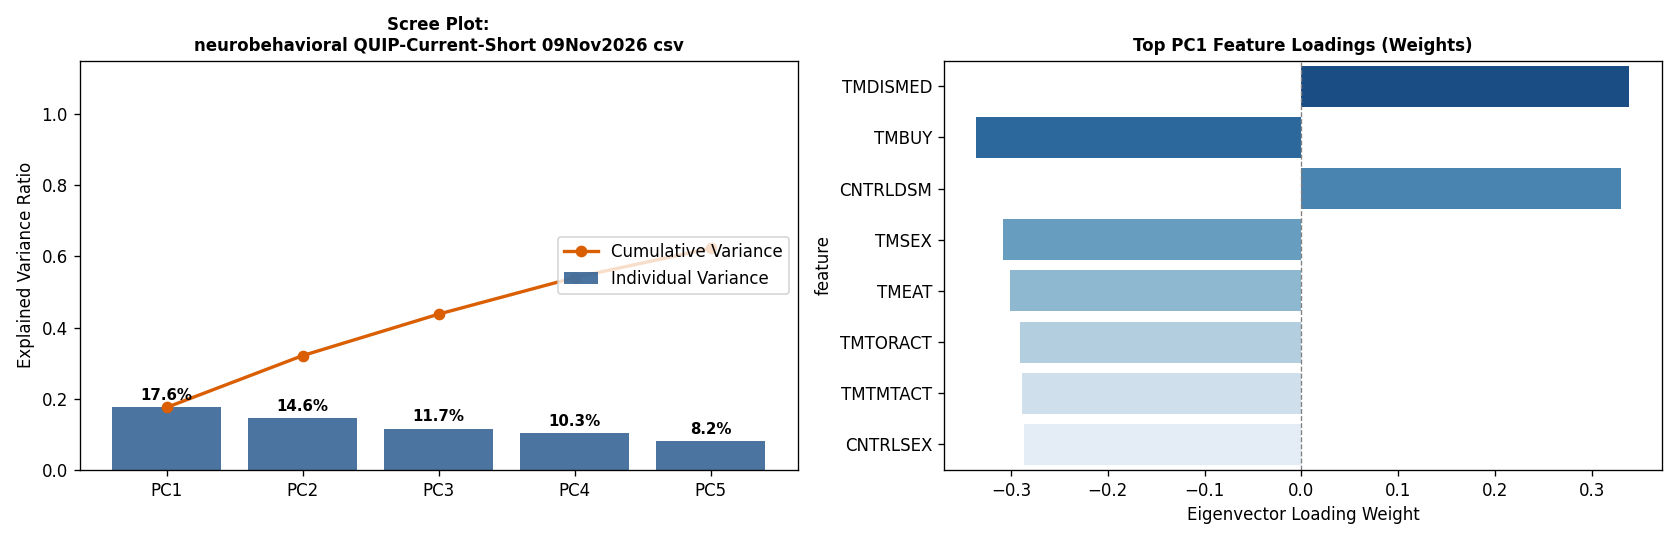

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


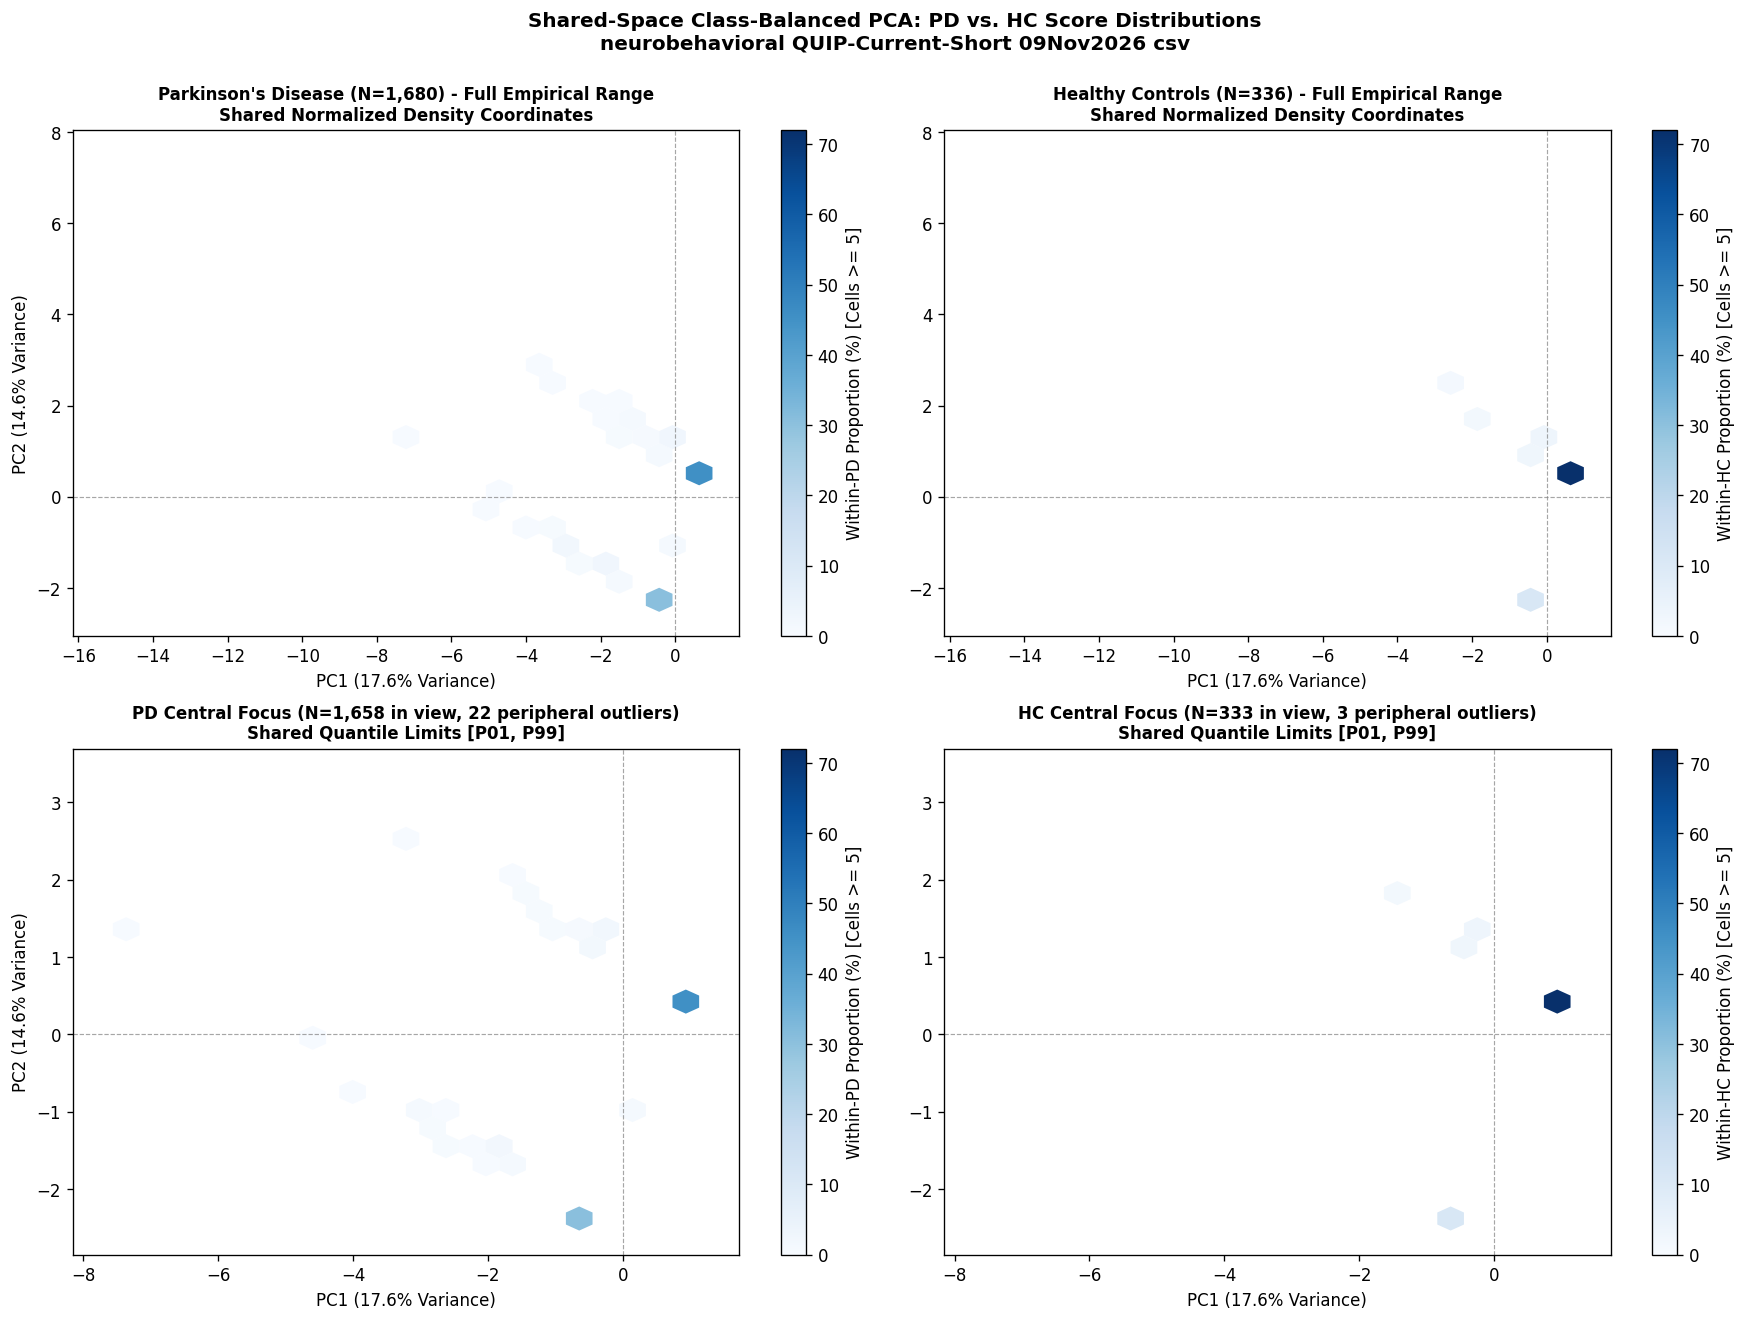

In [14]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neurobehavioral_QUIP-Current-Short_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neurobehavioral_QUIP-Current-Short_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 3. Modality Synthesis & Scientific Limitations

### Evidence-Bounded Findings
- **Data Coverage**: Analysis covered all 6 scoped analyzable unit(s) belonging to `Neurobehavioral, Sleep & Autonomic Systems`.
- **Shared Coordinate Space**: All participant-level PCAs were estimated in a deterministically balanced coordinate space combining Parkinson's disease and healthy control cohorts, which reduces direct sample-count influence on component orientation.
- **Variance Patterns**: Scree and loading structures demonstrate dominant sources of numeric variance within the retained continuous feature space for this modality.

### Methodological Limitations
1. **Unadjusted Covariates**: PCA projections represent unadjusted variance; age, sex, and disease duration effects are not regressed out.
2. **Missingness Imputation**: Median imputation fitted exclusively on the class-balanced training sample was applied to replace missing values in retained features (features with > 40% missingness excluded), preserving sample size rather than performing complete-case deletion.
3. **No Causal / Diagnostic Claims**: PCA scores reflect descriptive data geometry and must not be interpreted as validated diagnostic classifiers or clinical progression endpoints without formal hypothesis testing.